# **실습 개요**

이번 실습에서는 실제 비즈니스 데이터 대신, 이상치 탐지 알고리즘들의 특성을 명확하게 비교하기 위해 만든 **2차원 합성 데이터**를 사용합니다.
| 이상치 종류 | 설명 |
|---|---|
| **전역 이상치** (global) | 데이터 전체에서 멀리 떨어진, 누가 봐도 명백한 이상치 |
| **경계 이상치** (border) | 정상 군집의 가장자리 바로 바깥쪽에 위치한 이상치 |
| **국소 이상치** (local/contextual) | 두 군집 **사이의 빈 공간**에 위치 — x, x2 좌표 각각은 정상 범위 안에 있지만, 실제로는 그 조합의 데이터가 존재하지 않는 곳에 있는 이상치 |

## **1. 데이터 생성하기**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

rng = np.random.RandomState(42)

# 정상 데이터: 두 개의 초승달 모양 군집
X_moons, _ = make_moons(n_samples=320, noise=0.05, random_state=42)
X_moons = X_moons * 2.5

# 전역 이상치: 데이터 범위 밖 멀리 떨어진 점들
global_outliers = np.array([
    [6.5, 6.0], [-6.0, 5.5], [6.0, -5.5], [-6.5, -5.0], [0.0, 7.0], [7.0, 0.5],
])

# 국소 이상치: 두 초승달 사이 빈 공간
local_outliers = np.array([
    [1.2, 1.0], [1.3, 0.85], [1.1, 1.15], [1.35, 1.05], [1.0, 0.95],
])

# 경계 이상치: 하나의 초승달 바로 바깥쪽
border_outliers = np.array([
    [-2.8, 1.6], [5.4, 0.3], [3.0, -2.0],
])

X = np.vstack([X_moons, global_outliers, local_outliers, border_outliers])
true_label = np.array(
    ["normal"] * len(X_moons) +
    ["global"] * len(global_outliers) +
    ["local"] * len(local_outliers) +
    ["border"] * len(border_outliers)
)

In [2]:
df = pd.DataFrame(X, columns=["x1", "x2"])
df["true_label"] = true_label
df.head()

,x1,x2,true_label
0,0.065924,0.911657,normal
1,2.006306,-1.265495,normal
2,2.124983,1.083603,normal
3,0.510916,2.334814,normal
4,2.597618,0.400299,normal


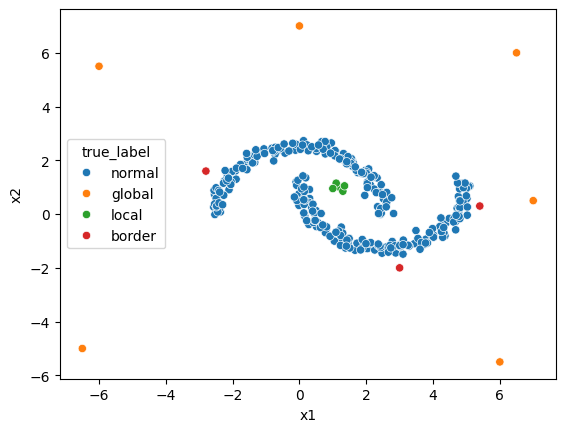

In [4]:
import seaborn as sns

sns.scatterplot(data=df, x="x1", y="x2", hue="true_label")
plt.show()

## **1-1 Feature Scaling**

**Q1. StandardScaler로 x1, x2를 표준화하세요.**
- 거리·밀도 기반 기법들이 각 축을 동일한 기준으로 비교할 수 있도록 스케일을 맞춰줍니다.

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["x1", "x2"]])
X_scaled[:5]

array([[-0.52417272,  0.19292738],
       [ 0.32555743, -1.34152498],
       [ 0.37752839,  0.31411427],
       [-0.32930201,  1.19596505],
       [ 0.58450422, -0.16747669]])

## **2. 이상치 탐지 기법 비교하기**

### **2-1 Z-score**

각 축에서 평균으로부터 표준편차 몇 배 떨어져 있는지를 봅니다.

두 축 중 하나라도 |z| > 3이면 이상치로 판단합니다.

**Q1. Z-score를 계산하여 이상치를 탐지하세요.**

In [7]:
z_scores = np.abs(X_scaled)
zscore_flag = (z_scores > 3).any(axis=1)
zscore_flag.sum()

np.int64(5)

**Q2. 탐지 결과를 산점도로 시각화하세요.**

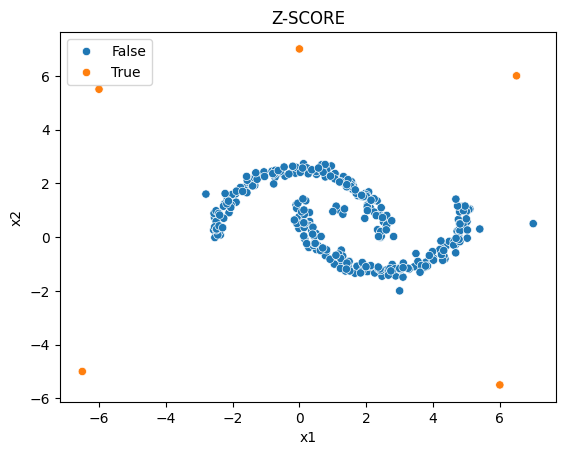

In [9]:
sns.scatterplot(data=df, x="x1", y="x2", hue=zscore_flag)
plt.title("Z-SCORE")
plt.show()

### **2-2 IQR**

사분위수(Q1, Q3)를 기준으로, 정상 범위([Q1-1.5·IQR, Q3+1.5·IQR])를 벗어나면 이상치로 판단합니다.

**Q1. IQR을 이용해 이상치를 탐지하세요.**

In [10]:
def find_whiskers(data, c):
    col = data[:, c]  # 모든 행, c번째 열
    Q1 = np.quantile(col, 0.25)
    Q3 = np.quantile(col, 0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return lower, upper

In [11]:
iqr_flag = np.zeros(len(X_scaled), dtype=bool)

for c in range(X_scaled.shape[1]):
  lower, upper = find_whiskers(X_scaled, c)
  iqr_flag |= (X_scaled[:, c] < lower) | (X_scaled[:, c] > upper)

**Q2. 탐지 결과를 산점도로 시각화하세요.**

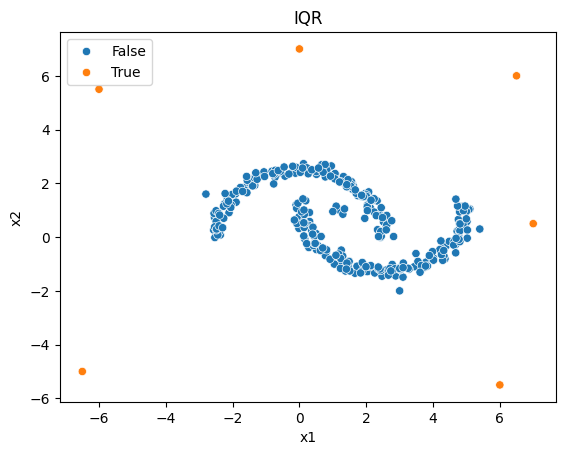

In [13]:
sns.scatterplot(data=df, x="x1", y="x2", hue=iqr_flag)
plt.title("IQR")
plt.show()

### **2.3 KNN Distance**

**Q1. NearestNeighbors(k=6)로 평균 이웃 거리를 계산하고, 거리가 상위 5%인 점을 이상치로 탐지하세요.**
- 자기 자신은 이웃에서 제외해야 합니다(`n_neighbors=7`로 구한 뒤 첫 번째 이웃을 제외).

In [14]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=7)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
knn_score = distances[:, 1:].mean(axis=1)  # 첫 번째(자기 자신, 거리 0) 제외

threshold = np.quantile(knn_score, 0.95)
knn_flag = knn_score > threshold
knn_flag.sum()

np.int64(17)

**Q2. 탐지 결과를 산점도로 시각화하세요.**

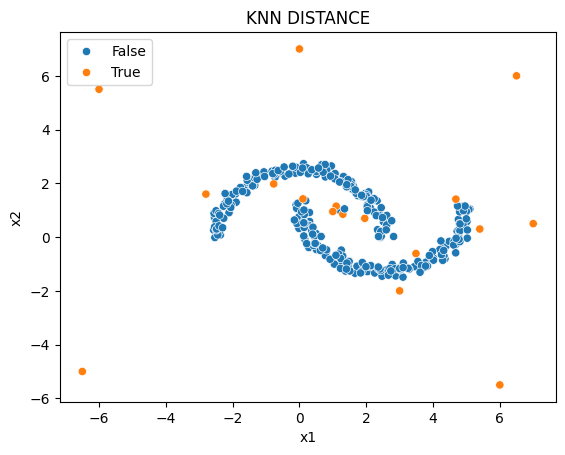

In [16]:
sns.scatterplot(data=df, x="x1", y="x2", hue=knn_flag)
plt.title("KNN DISTANCE")
plt.show()

### **2.4 LOF**

In [18]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=7, contamination=0.05)
pred = lof.fit_predict(X_scaled)
lof_flag = pred==-1

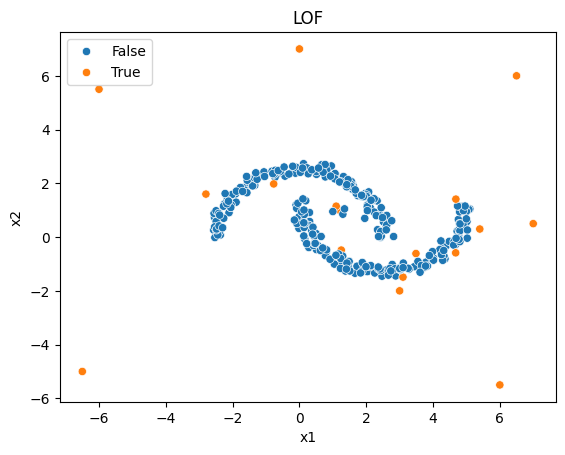

In [19]:
sns.scatterplot(data=df, x="x1", y="x2", hue=lof_flag)
plt.title("LOF")
plt.show()

### **2.5 Isolation Forest**

무작위로 데이터를 분할하는 트리를 여러 개 만들어, 적은 분할 횟수만으로 고립되는 데이터를 이상치로 판단합니다.

**Q1. `IsolationForest`(`contamination=0.03`)로 이상치를 탐지하세요.**

In [20]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=100, contamination=0.03, random_state=42)
iso.fit(X_scaled)

iso_flag = iso.predict(X_scaled) == -1
iso_flag.sum()

np.int64(10)

**Q2. 탐지 결과를 산점도로 시각화하세요.**

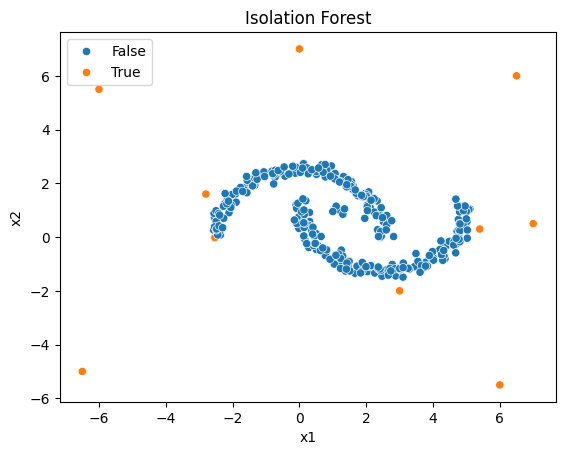

In [22]:
sns.scatterplot(data=df, x="x1", y="x2", hue=iso_flag)
plt.title("Isolation Forest")
plt.show()

### **2.6 GMM (Gaussian Mixture Model)**

데이터가 여러 개의 가우시안(정규) 분포가 섞여 만들어졌다고 가정하고 그 분포를 학습합니다. 우도(likelihood)가 낮은 데이터를 이상치로 판단합니다.

**Q1. GaussianMixture(n_components=2)로 우도가 하위 3%인 데이터를 이상치로 탐지하세요.**

In [24]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=2, random_state=42)
gmm.fit(X_scaled)

log_likelihood = gmm.score_samples(X_scaled)
threshold = np.quantile(log_likelihood, 0.05)
gmm_flag = log_likelihood < threshold
gmm_flag.sum()

np.int64(17)

**Q2. 탐지 결과를 산점도로 시각화하세요.**

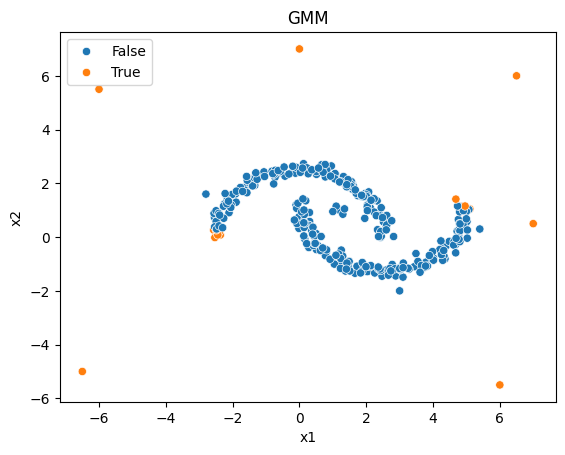

In [26]:
sns.scatterplot(data=df, x="x1", y="x2", hue=gmm_flag)
plt.title("GMM")
plt.show()

### **2.7 One-Class SVM**

정상 데이터를 감싸는 경계(boundary)를 학습하고, 그 경계 밖의 데이터를 이상치로 판단합니다.

**Q1. OneClassSVM(nu=0.03)으로 이상치를 탐지하세요.**

In [27]:
from sklearn.svm import OneClassSVM

ocsvm = OneClassSVM(nu=0.05, kernel="rbf", gamma=0.1)
ocsvm.fit(X_scaled)

ocsvm_flag = ocsvm.predict(X_scaled) == -1
ocsvm_flag.sum()

np.int64(17)

**Q2. 탐지 결과를 산점도로 시각화하세요.**

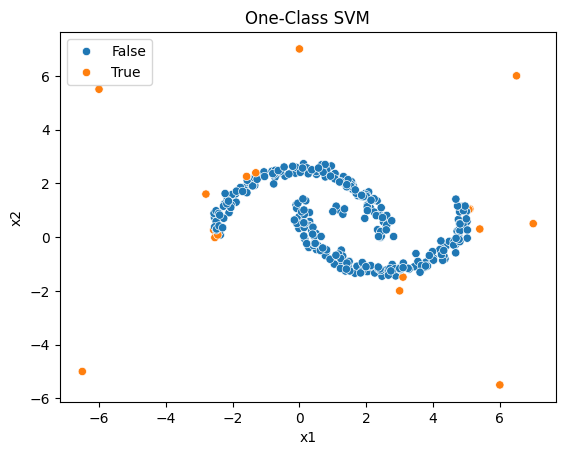

In [29]:
sns.scatterplot(df, x='x1', y='x2', hue=ocsvm_flag)
plt.title("One-Class SVM")
plt.show()